In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import cos, sin, asin, sqrt, pi

# Assignment Problems: Day 3
The following problems require access to the file named ‘Dataset_Day3.csv’, provided with this assignment.

About the data,

* key - a unique identifier for each trip
* fare_amount - the cost of each trip in usd
* pickup_datetime - date and time when the meter was engaged
* passenger_count - the number of passengers in the vehicle (driver entered value)
* pickup_longitude - the longitude where the meter was engaged
* pickup_latitude - the latitude where the meter was engaged
* dropoff_longitude - the longitude where the meter was disengaged
* dropoff_latitude - the latitude where the meter was disengaged

In [3]:
data = pd.read_csv("Dataset_Day3.csv")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   key                200000 non-null  int64  
 1   fare_amount        200000 non-null  float64
 2   pickup_datetime    200000 non-null  object 
 3   pickup_longitude   200000 non-null  float64
 4   pickup_latitude    200000 non-null  float64
 5   dropoff_longitude  199999 non-null  float64
 6   dropoff_latitude   199999 non-null  float64
 7   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 12.2+ MB


### question - 1
###### Use the location coordinates to find the distance for each trip. Create a new column – ‘distance’ and store its value there. Use the following formula:

In [383]:
data = data.dropna()

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   key                200000 non-null  int64  
 1   fare_amount        200000 non-null  float64
 2   pickup_datetime    200000 non-null  object 
 3   pickup_longitude   200000 non-null  float64
 4   pickup_latitude    200000 non-null  float64
 5   dropoff_longitude  199999 non-null  float64
 6   dropoff_latitude   199999 non-null  float64
 7   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 12.2+ MB


In [5]:
def distance(lon1, lat1, lon2, lat2):
#    return = 2*6371*asin(sqrt(sin(((lat2-lat1)*pi/360)**2 + cos(lat1*pi/180) * cos(lat2*pi/180) * sin((lon2 - lon1)*pi/360)**2))
    return sqrt((lat1-lat2)**2 + (lon1-lon2)**2)

In [6]:
data['distance'] = data.apply(lambda x: distance(x['pickup_longitude'], x['pickup_latitude'], x['dropoff_longitude'], x['dropoff_latitude']), axis = 1)

In [373]:
data['fare_amount'] = data['fare_amount']/data['passenger_count']
data

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,24238194,7.500000,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,0.015140
1,27835199,7.700000,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,0.022103
2,44984355,12.900000,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,0.053109
3,25894730,1.766667,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,0.016528
4,17610152,3.200000,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,0.051031
...,...,...,...,...,...,...,...,...,...
199995,42598914,3.000000,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1,0.001064
199996,16382965,7.500000,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1,0.022126
199997,27804658,15.450000,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2,0.142223
199998,20259894,14.500000,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695416,1,0.033101


### question - 2
###### Find all the ‘key’ values for which the attributes: fare_amount & passenger_count & distance are outliers. Remove all rows with outliers.

In [13]:
# using iqr method

temp = data[["fare_amount","passenger_count","distance"]]
bod = pd.DataFrame()
for col in ["fare_amount"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
d_bod_free1 = data.drop(bod.index,axis=0)

temp = d_bod_free1[["fare_amount","passenger_count","distance"]]
bod = pd.DataFrame()
for col in ["passenger_count"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
d_bod_free2 = d_bod_free1.drop(bod.index,axis=0)

temp = d_bod_free2[["fare_amount","passenger_count","distance"]]
bod = pd.DataFrame()
for col in ["distance"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
d_bod_free = d_bod_free2.drop(bod.index,axis=0)


# we can use this commented portion to further reduce the spread of the data by serialising it in loop

# for i in range(1,10):
#     temp = d_bod_free[["fare_amount","passenger_count","distance"]]
#     bod = pd.DataFrame()
#     for col in ["fare_amount"]:
#         Q1 = temp[col].quantile(0.25)
#         Q3 = temp[col].quantile(0.75)
#         IQR = Q3 - Q1
#         UpperBound = Q3 + 1.5*IQR
#         LowerBound = Q1 - 1.5*IQR
#         bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
#     d_bod_free1 = d_bod_free.drop(bod.index,axis=0)
#     temp = d_bod_free1[["fare_amount","passenger_count","distance"]]
#     bod = pd.DataFrame()
#     for col in ["passenger_count"]:
#         Q1 = temp[col].quantile(0.25)
#         Q3 = temp[col].quantile(0.75)
#         IQR = Q3 - Q1
#         UpperBound = Q3 + 1.5*IQR
#         LowerBound = Q1 - 1.5*IQR
#         bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
#     d_bod_free2 = d_bod_free1.drop(bod.index,axis=0)
#     temp = d_bod_free2[["fare_amount","passenger_count","distance"]]
#     bod = pd.DataFrame()
#     for col in ["distance"]:
#         Q1 = temp[col].quantile(0.25)
#         Q3 = temp[col].quantile(0.75)
#         IQR = Q3 - Q1
#         UpperBound = Q3 + 1.5*IQR
#         LowerBound = Q1 - 1.5*IQR
#         bod[col] = temp[col][(temp[col]<LowerBound) | (temp[col]>UpperBound)]
#     d_bod_free = d_bod_free2.drop(bod.index,axis=0)

data['key'][d_bod_free.index]

0         24238194
1         27835199
5         44470845
7         44195482
8         15822268
            ...   
199994     3189201
199995    42598914
199996    16382965
199998    20259894
199999    11951496
Name: key, Length: 110830, dtype: int64

In [7]:
# using z-score

temp = data[["fare_amount","passenger_count","distance"]]
zod = pd.DataFrame()
for col in ["fare_amount"]:
    z_score = (temp[col] - temp[col].mean())/temp[col].std()
    zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
d_zod_free1 = data.drop(zod.index,axis=0)


# we can use this commented portion to further reduce the spread of the data
# by applying this procedure on previosly obtained outlier free data

# temp = d_bod_free[["fare_amount","passenger_count","distance"]]
# zod = pd.DataFrame()
# for col in ["fare_amount"]:
#     z_score = (temp[col] - temp[col].mean())/temp[col].std()
#     zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
# d_zod_free1 = d_bod_free.drop(zod.index,axis=0)

temp = d_zod_free1[["fare_amount","passenger_count","distance"]]
zod = pd.DataFrame()
for col in ["passenger_count"]:
    z_score = (temp[col] - temp[col].mean())/temp[col].std()
    zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
d_zod_free2 = d_zod_free1.drop(zod.index,axis=0)

temp = d_zod_free2[["fare_amount","passenger_count","distance"]]
zod = pd.DataFrame()
for col in ["distance"]:
    z_score = (temp[col] - temp[col].mean())/temp[col].std()
    zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
d_zod_free = d_zod_free2.drop(zod.index,axis=0)


# we can use this commented portion to further reduce the spread of the data by serialising it in loop

# for i in range(1,10):
#     temp = d_zod_free2[["fare_amount","passenger_count","distance"]]
#     zod = pd.DataFrame()
#     for col in ["fare_amount"]:
#         z_score = (temp[col] - temp[col].mean())/temp[col].std()
#         zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
#     d_zod_free1 = d_zod_free2.drop(zod.index,axis=0)
#     temp = d_zod_free1[["fare_amount","passenger_count","distance"]]
#     zod = pd.DataFrame()
#     for col in ["passenger_count"]:
#         z_score = (temp[col] - temp[col].mean())/temp[col].std()
#         zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
#     d_zod_free2 = d_zod_free1.drop(zod.index,axis=0)
#     temp = d_zod_free2[["fare_amount","passenger_count","distance"]]
#     zod = pd.DataFrame()
#     for col in ["distance"]:
#         z_score = (temp[col] - temp[col].mean())/temp[col].std()
#         zod[col] = temp[col][(z_score > 3) | (z_score < -3)]
#     d_zod_free = d_zod_free2.drop(zod.index,axis=0)

data['key'][d_zod_free.index]

0         24238194
1         27835199
2         44984355
3         25894730
4         17610152
            ...   
199995    42598914
199996    16382965
199997    27804658
199998    20259894
199999    11951496
Name: key, Length: 190046, dtype: int64

### question - 3
###### Show the scatterplot between distance & fare_amount. Is there any relationship that you can identify?

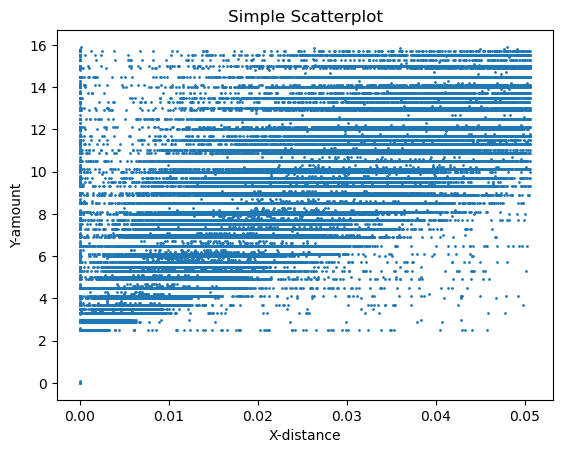

In [14]:
plt.scatter(d_bod_free["distance"],d_bod_free["fare_amount"],1)
plt.title('Simple Scatterplot')
plt.xlabel('X-distance')
plt.ylabel('Y-amount')
plt.show()

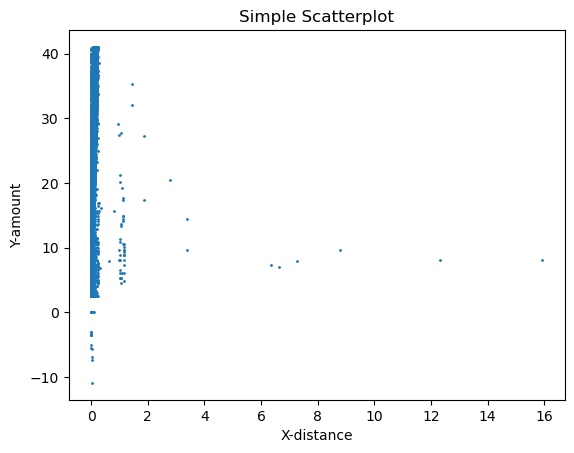

In [8]:
plt.scatter(d_zod_free["distance"],d_zod_free["fare_amount"],1)
plt.title('Simple Scatterplot')
plt.xlabel('X-distance')
plt.ylabel('Y-amount')
plt.show()

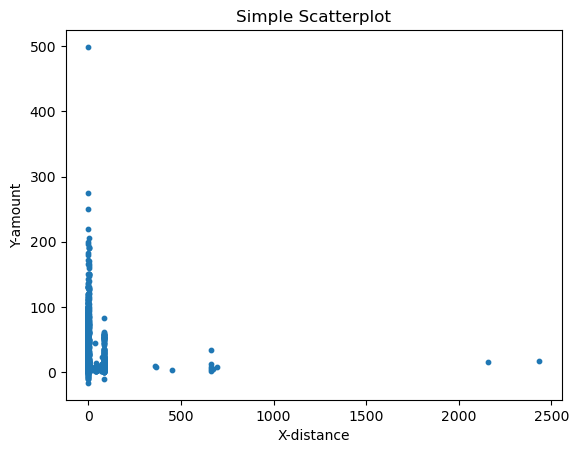

In [386]:
plt.scatter(data["distance"],data["fare_amount"],10)
plt.title('Simple Scatterplot')
plt.xlabel('X-distance')
plt.ylabel('Y-amount')
plt.show()